In [1]:
## %% [markdown]
# # 02. PCA of the compositional space and the pool of unfilled regions
# Project: Fe-Ni-Co-Al-Cr-Ti alloy composition space


In [2]:
## %% [markdown]
# # 02. PCA of the compositional space and the pool of unfilled regions
# Project: Fe-Ni-Co-Al-Cr-Ti alloy composition space


In [3]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

from src.alloy_space.descriptors import calculate_descriptors

FIGURES_DIR = BASE_DIR / "outputs" / "figures"
TABLES_DIR = BASE_DIR / "outputs" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", font_scale=1.05)
plt.rcParams['figure.dpi'] = 120


In [4]:
# 1. Loading unique compositions and distributions of the base elements
df_comp = pd.read_parquet(
    BASE_DIR / "data" / "processed" / "dataset_compositions_unique.parquet"
)

BASE_6 = ["Ni", "Co", "Fe", "Cr", "Al", "Ti"]
missing = [el for el in BASE_6 if el not in df_comp.columns]
if missing:
    raise ValueError(f"Base-element columns are missing: {missing}")

N_ALLOYS = len(df_comp)
X_base6 = df_comp[BASE_6].to_numpy(dtype=float)

if N_ALLOYS == 0:
    raise ValueError("The sample of unique compositions is empty.")
if not np.isfinite(X_base6).all():
    raise ValueError("Concentrations contain NaN or infinite values.")
if ((X_base6 < 0) | (X_base6 > 100)).any():
    raise ValueError("Some concentrations are outside the 0–100 at.% range.")


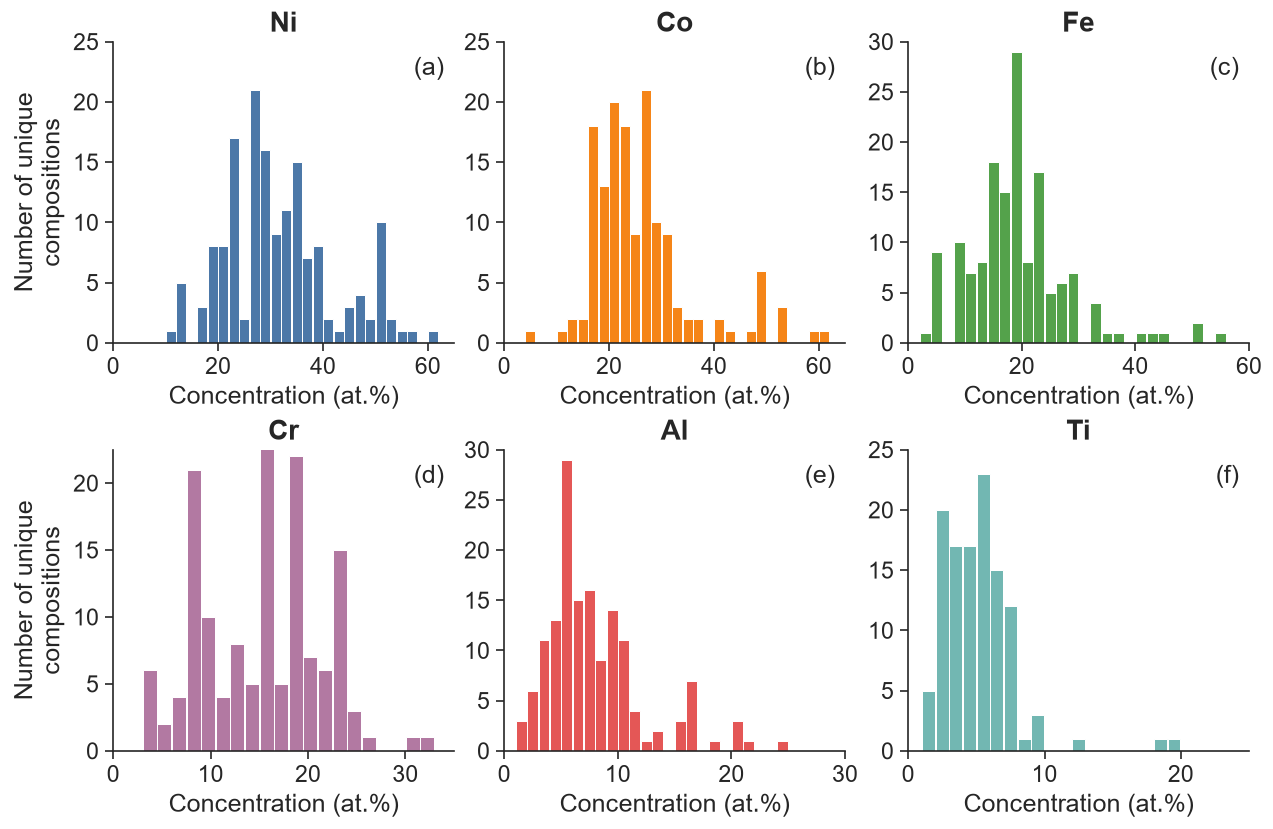

In [17]:
# Histograms of the base-element concentrations (nonzero values only)

# Bin widths, one per element (bin edges start at 0)
BIN_WIDTHS = {
    "Ni": 2.0,
    "Co": 2.0,
    "Fe": 2.0,
    "Cr": 1.5,
    "Al": 1.0,
    "Ti": 1.0,
}

ELEMENT_COLORS = {
    "Ni": "#4C78A8",  # blue
    "Co": "#F58518",  # orange
    "Fe": "#54A24B",  # green
    "Cr": "#B279A2",  # purple
    "Al": "#E45756",  # red
    "Ti": "#72B7B2",  # turquoise
}

Y_MAX = {
    "Ni": 25,
    "Co": 25,
    "Fe": 30,
    "Cr": 22.5,
    "Al": 30,
    "Ti": 25,
}

X_MAX = {
    "Ni": 65,
    "Co": 65,
    "Fe": 60,
    "Cr": 35,
    "Al": 30,
    "Ti": 25,
}

# Font sizes (pt). The figure is scaled down in the paper (10.5 in -> ~7 in, factor ~0.67),
# so the printed size is roughly 2/3 of these values.
FONT_BASE = 14
FONT_LABEL = 15
FONT_TITLE = 17
FONT_TICK = 14
FONT_PANEL = 15

with plt.rc_context({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.transparent": False,
    "font.family": "sans-serif",
    "font.size": FONT_BASE,
    "axes.labelsize": FONT_LABEL,
    "axes.titlesize": FONT_TITLE,
    "axes.titleweight": "bold",
    "xtick.labelsize": FONT_TICK,
    "ytick.labelsize": FONT_TICK,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "axes.linewidth": 1.0,
    "pdf.fonttype": 42,
}):
    fig_hist, axes_hist = plt.subplots(
        2, 3,
        figsize=(10.5, 6.8),
        sharex=False,
        sharey=False,
        constrained_layout=True,
    )

    for panel, ax, element in zip("abcdef", axes_hist.flat, BASE_6):
        values = df_comp[element].to_numpy(dtype=float)
        values = values[values > 0]

        bin_width = BIN_WIDTHS[element]
        if bin_width <= 0:
            raise ValueError(f"{element}: the bin width must be positive.")

        max_value = values.max() if values.size else 0.0
        n_bins = max(1, int(np.ceil(max_value / bin_width)))
        bin_edges = np.arange(n_bins + 1) * bin_width

        counts, _, _ = ax.hist(
            values,
            bins=bin_edges,
            rwidth=0.95,
            color=ELEMENT_COLORS[element],
            edgecolor="white",
            linewidth=0.6,
        )

        if int(counts.sum()) != len(values):
            raise ValueError(
                f"{element}: not all nonzero concentrations fell into the histogram."
            )

        ax.set_title(element)
        ax.set_xlabel("Concentration (at.%)")
        ax.set_xlim(0, X_MAX[element])
        ax.set_ylim(0, Y_MAX[element])
        ax.text(
            0.97, 0.95, f"({panel})",
            transform=ax.transAxes,
            ha="right", va="top",
            fontsize=FONT_PANEL,
        )
        ax.tick_params(axis="x", labelbottom=True)
        ax.grid(False)

    for ax in axes_hist[:, 0]:
        ax.set_ylabel("Number of unique\ncompositions")

    sns.despine(fig=fig_hist)

    hist_output = FIGURES_DIR / "base6_concentration_histograms"
    fig_hist.savefig(hist_output.with_suffix(".pdf"), bbox_inches="tight")
    fig_hist.savefig(
        hist_output.with_suffix(".png"),
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()

In [6]:
# 2. Additional elements and Al+Ti, Al/Ti descriptors
EXTRA_ELEMENTS = [
    'Cu', 'V', 'Mo', 'Hf', 'W', 'Ta', 'B', 'C', 'Nb', 'Mn'
]

df_comp['Additional elements (at.%)'] = df_comp.apply(
    lambda row: ', '.join(
        f"{el} = {row[el]:g}"
        for el in EXTRA_ELEMENTS
        if pd.notna(row[el]) and row[el] > 0
    ),
    axis=1
)

# Al+Ti and Al/Ti for the literature compositions (for Fig. 08 and the text about the window)
df_comp['Al_plus_Ti'] = df_comp['Al'] + df_comp['Ti']
df_comp['Al_to_Ti_ratio'] = df_comp['Al'] / df_comp['Ti'].replace(0, np.nan)

cols = ['Al_plus_Ti', 'Al_to_Ti_ratio']
print(f"Literature compositions: {N_ALLOYS}")
print("All compositions:")
print(df_comp[cols].describe(percentiles=[.05, .5, .95]).round(2).to_string())
print("\nCompositions with Target state = 1:")
print(df_comp.loc[df_comp['Target state'] == 1, cols]
      .describe(percentiles=[.05, .5, .95]).round(2).to_string())


Literature compositions: 161
All compositions:
       Al_plus_Ti  Al_to_Ti_ratio
count      161.00          116.00
mean        10.71            1.67
std          5.63            1.27
min          0.00            0.00
5%           4.00            0.23
50%          9.10            1.35
95%         17.30            3.29
max         40.00            8.00

Compositions with Target state = 1:
       Al_plus_Ti  Al_to_Ti_ratio
count       87.00           77.00
mean        10.46            1.67
std          3.75            1.33
min          2.70            0.00
5%           5.30            0.50
50%          9.10            1.30
95%         16.10            3.03
max         18.10            8.00


In [7]:
# 3. PCA on standardized concentrations of the base elements
scaler_base6 = StandardScaler()
X_base6_scaled = scaler_base6.fit_transform(X_base6)

pca = PCA(n_components=len(BASE_6))
X_pca_full = pca.fit_transform(X_base6_scaled)

for i in range(3):
    df_comp[f'PC{i + 1}'] = X_pca_full[:, i]

exp_var = pca.explained_variance_ratio_ * 100
variance_table = pd.DataFrame({
    'Component': [f'PC{i + 1}' for i in range(len(exp_var))],
    'Explained variance, %': exp_var.round(2),
    'Cumulative, %': np.cumsum(exp_var).round(2)})
print(variance_table.to_string(index=False))

loadings = pd.DataFrame(pca.components_[:3].T, columns=['PC1', 'PC2', 'PC3'], index=BASE_6)
print("\n=== Element loadings on PC1–PC3 ===")
print(loadings.round(3))
print("\n=== Element contribution to the variance of each axis, % ===")
print(((loadings ** 2) * 100).round(1))

with pd.ExcelWriter(TABLES_DIR / "pca_summary.xlsx", engine="openpyxl") as writer:
    variance_table.to_excel(writer, sheet_name="Explained_variance", index=False)
    loadings.round(4).rename_axis("Element").reset_index().to_excel(
        writer, sheet_name="Loadings_PC1-3", index=False)


Component  Explained variance, %  Cumulative, %
      PC1                  28.89          28.89
      PC2                  24.10          52.99
      PC3                  18.01          71.00
      PC4                  15.94          86.94
      PC5                  12.17          99.12
      PC6                   0.88         100.00

=== Element loadings on PC1–PC3 ===
      PC1    PC2    PC3
Ni  0.667 -0.111  0.020
Co -0.500 -0.569 -0.180
Fe -0.229  0.658 -0.304
Cr -0.127  0.126  0.927
Al  0.301  0.299 -0.117
Ti  0.381 -0.354 -0.052

=== Element contribution to the variance of each axis, % ===
     PC1   PC2   PC3
Ni  44.5   1.2   0.0
Co  25.0  32.4   3.2
Fe   5.2  43.2   9.2
Cr   1.6   1.6  85.9
Al   9.1   9.0   1.4
Ti  14.5  12.6   0.3


In [8]:
# 4. 3D grid, back-transformation to compositions, L1_2 window, gap pool
MARGIN, GRID_N = 0.15, 35
pcs = df_comp[['PC1', 'PC2', 'PC3']].values

axes_1d = [np.linspace(pcs[:, k].min() - MARGIN * np.ptp(pcs[:, k]),
                       pcs[:, k].max() + MARGIN * np.ptp(pcs[:, k]), GRID_N) for k in range(3)]
grid = np.column_stack([g.ravel() for g in np.meshgrid(*axes_1d)])

nn = NearestNeighbors(n_neighbors=1).fit(pcs)
df_grid = pd.DataFrame(grid, columns=['PC1', 'PC2', 'PC3'])
df_grid['dist_to_nearest_alloy'] = nn.kneighbors(grid)[0].ravel()

full = np.zeros((len(grid), pca.n_components_))
full[:, :3] = grid
comp = pd.DataFrame(scaler_base6.inverse_transform(pca.inverse_transform(full)), columns=BASE_6)
df_grid = pd.concat([df_grid, comp], axis=1)

df_valid = df_grid[(df_grid[BASE_6] >= -1.0).all(axis=1)].copy()
df_valid[BASE_6] = df_valid[BASE_6].clip(lower=0)
df_valid[BASE_6] = df_valid[BASE_6].div(df_valid[BASE_6].sum(axis=1), axis=0) * 100.0
df_valid = pd.concat([df_valid, calculate_descriptors(df_valid)], axis=1)

def in_l12_window(d):
    return ((d['VEC'] >= 7.85)
            & d['Al_plus_Ti'].between(8.0, 12.5)
            & d['Al_to_Ti_ratio'].between(0.9, 2.2)
            & (d['delta_atomic_radius'] <= 6.0))

valid_l12 = df_valid[in_l12_window(df_valid)].copy()
gap_threshold = float(np.percentile(valid_l12['dist_to_nearest_alloy'], 85))
gap_pool = valid_l12[valid_l12['dist_to_nearest_alloy'] >= gap_threshold].copy()

print(f"Grid nodes: {len(df_grid)}; physically valid: {len(df_valid)}; "
      f"in the L1_2 window: {len(valid_l12)}; 85th-percentile threshold: {gap_threshold:.3f}; pool: {len(gap_pool)}")
pool_cols = BASE_6 + ['VEC', 'Al_plus_Ti', 'Al_to_Ti_ratio', 'delta_atomic_radius', 'dist_to_nearest_alloy']
gap_pool[pool_cols].round(2).to_excel(TABLES_DIR / "pca3d_gap_pool_base6.xlsx", index=False)


Grid nodes: 42875; physically valid: 12798; in the L1_2 window: 887; 85th-percentile threshold: 0.907; pool: 133


In [9]:
# 5. Candidates (selected manually from the interactive 3D plot) and the melted samples
CANDIDATES = pd.DataFrame([
    [38.81, 28.87, 5.04, 15.25, 5.80, 6.22],  # 1
    [33.65, 25.21, 4.62, 27.22, 4.80, 4.49],  # 2
    [37.20, 19.68, 1.20, 31.94, 5.10, 4.89],  # 3
    [40.61, 14.79, 5.84, 26.59, 7.02, 5.15],  # 4
    [28.37, 22.78, 13.12, 27.48, 5.57, 2.68],  # 5
    [32.87, 36.51, 16.60, 2.17, 6.59, 5.26],  # 6
    [26.35, 40.65, 20.19, 3.12, 5.76, 3.93],  # 7
    [26.96, 42.35, 14.60, 7.05, 4.65, 4.39],  # 8
    [25.49, 48.32, 16.07, 1.14, 4.36, 4.62],  # 9
    [22.27, 45.77, 22.79, 0.59, 5.20, 3.37],  # 10
    [41.81, 20.62, 2.04, 23.16, 6.20, 6.17],  # 11
    [41.34, 18.65, 0.00, 28.39, 5.71, 5.91],  # 12
], columns=BASE_6)
CANDIDATES.insert(0, 'Alloy_Number', range(1, len(CANDIDATES) + 1))
CANDIDATES['Cluster'] = ['Upper'] * 5 + ['Lower'] * 5 + ['Upper'] * 2  # 11-12: please verify

def project(comp_df):
    X = comp_df[BASE_6].values.astype(float)
    z = pca.transform(scaler_base6.transform(X))
    out = comp_df.copy()
    out[['PC1', 'PC2', 'PC3']] = z[:, :3]
    return out

cand = project(CANDIDATES)
cand = pd.concat([cand, calculate_descriptors(cand)], axis=1)
cand['in_L12_window'] = in_l12_window(cand)
cand['dist_to_nearest_alloy'] = nn.kneighbors(cand[['PC1', 'PC2', 'PC3']].values)[0].ravel()
cand['beyond_gap_threshold'] = cand['dist_to_nearest_alloy'] >= gap_threshold
print("Candidate composition sums:", CANDIDATES[BASE_6].sum(axis=1).round(2).tolist())
print(cand[['Alloy_Number', 'Cluster', 'Al_plus_Ti', 'Al_to_Ti_ratio', 'VEC',
            'in_L12_window', 'dist_to_nearest_alloy', 'beyond_gap_threshold']].round(2).to_string(index=False))
cand.round(3).to_excel(TABLES_DIR / "candidates_12.xlsx", index=False)

# Experimental compositions of the melts for the initial candidates No. 1–12
EXPERIMENTAL = pd.DataFrame([
    [38.19, 29.31, 5.28, 15.51, 5.39, 6.33],  # 1
    [32.70, 25.30, 4.76, 27.65, 4.99, 4.62],  # 2
    [34.41, 23.90, 1.33, 30.41, 5.05, 4.91],  # 3
    [40.06, 14.91, 6.11, 27.09, 6.71, 5.15],  # 4
    [27.74, 22.80, 13.18, 27.77, 5.87, 2.64],  # 5
    [32.07, 36.64, 17.07, 2.29, 6.64, 5.31],  # 6
    [25.81, 40.68, 20.64, 3.20, 5.79, 3.89],  # 7
    [26.21, 42.24, 14.95, 7.36, 4.85, 4.41],  # 8
    [24.64, 48.37, 16.57, 1.23, 4.54, 4.67],  # 9
    [21.80, 45.59, 23.37, 0.56, 5.31, 3.38],  # 10
    [40.54, 20.53, 2.14, 23.41, 7.09, 6.31],  # 11
    [40.55, 18.82, 0.00, 29.08, 5.56, 6.00],  # 12
], columns=BASE_6)

EXPERIMENTAL.insert(0, 'Alloy_Number', range(1, len(EXPERIMENTAL) + 1))
EXPERIMENTAL['Cluster'] = ['Upper'] * 5 + ['Lower'] * 5 + ['Upper'] * 2

experimental = project(EXPERIMENTAL)
experimental['dist_to_nearest_alloy'] = nn.kneighbors(
    experimental[['PC1', 'PC2', 'PC3']].values
)[0].ravel()

print(
    "Experimental composition sums:",
    EXPERIMENTAL[BASE_6].sum(axis=1).round(4).tolist()
)


Candidate composition sums: [99.99, 99.99, 100.01, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 99.99, 100.0, 100.0]
 Alloy_Number Cluster  Al_plus_Ti  Al_to_Ti_ratio  VEC  in_L12_window  dist_to_nearest_alloy  beyond_gap_threshold
            1   Upper       12.02            0.93 8.22           True                   1.03                  True
            2   Upper        9.29            1.07 7.96           True                   0.94                  True
            3   Upper        9.99            1.04 7.85           True                   1.27                  True
            4   Upper       12.17            1.36 7.87           True                   0.92                  True
            5   Upper        8.25            2.08 7.86           True                   0.93                  True
            6   Lower       11.85            1.25 8.44           True                   0.87                 False
            7   Lower        9.69            1.47 8.43           True            

In [10]:
# 6. Final plot
import plotly.graph_objects as go

LABELS = {
    'lit': 'Literature alloys',
    'pool': 'Composition gaps',
    'cand': 'Candidate alloys',
    'exp': 'Experimental alloys',
}

CAMERA = dict(
    eye=dict(x=-1.42, y=-1.76, z=0.71),
    up=dict(x=0.26, y=0.25, z=0.93),
    center=dict(x=-0.30, y=0.24, z=-0.15),
)
VIEWS = {
    "Default": CAMERA,
    "Upper cluster": dict(
        eye=dict(x=0.86, y=0.11, z=0.56),
        up=dict(x=-0.31, y=-0.27, z=0.91),
        center=dict(x=0.16, y=-0.42, z=0.17),
    ),
    "Bottom cluster": dict(
        eye=dict(x=-0.61, y=-1.00, z=-0.28),
        up=dict(x=0.02, y=0.00, z=1.00),
        center=dict(x=-0.13, y=0.01, z=-0.29),
    ),
}
FONT_SIZE = 14
LEGEND_FONT_SIZE = 17
KEY_FONT_SIZE = 17
AXIS_COLOR = "#2A3F5F"
POSITIVE_COLOR = "#166534"
NEGATIVE_COLOR = "#B22222"
NEUTRAL_COLOR = "#444444"

def fmt(v):
    return f"{v:.2f}" if isinstance(v, (float, np.floating)) else str(v)

def hover_text(df, prefix=None, extra=()):
    out = []
    for i, (_, r) in enumerate(df.iterrows()):
        head = f"<b>{prefix[i]}</b><br>" if prefix is not None else ""
        comps = ", ".join(f"{c}={r[c]:.1f}" for c in BASE_6)
        tail = "".join(
            f"<br><b>{c}</b>: {fmt(r[c])}"
            for c in extra
            if pd.notna(r[c]) and r[c] != ''
        )
        out.append(head + comps + tail)
    return out


In [11]:
# Links between the upper-cluster candidates (formerly yellow + formerly turquoise)
UPPER_LINKS = [
    (5, 4), (5, 2), (5, 3), (3, 4), (3, 2), (1, 4), (1, 2),  # were yellow
    (12, 2), (12, 3), (12, 4), (12, 11), (11, 1), (11, 2), (11, 4),  # were turquoise
]
LOWER_LINKS = [(10, 7), (10, 9), (10, 8), (8, 7), (8, 9), (6, 8), (6, 9), (6, 7)]  # lower cluster to be tuned later
LINKS = sorted({tuple(sorted(p)) for p in UPPER_LINKS + LOWER_LINKS})
LINK_COLOR = 'goldenrod'

points_by_number = {int(r.Alloy_Number): (r.PC1, r.PC2, r.PC3) for r in cand.itertuples()}
assert all(a in points_by_number and b in points_by_number for a, b in LINKS), "Link refers to a non-existent number"

def links_trace(pairs, color=LINK_COLOR, name='Links between candidates', width=4):
    xs, ys, zs = [], [], []
    for a, b in pairs:
        pa, pb = points_by_number[a], points_by_number[b]
        xs += [pa[0], pb[0], None]
        ys += [pa[1], pb[1], None]
        zs += [pa[2], pb[2], None]
    return go.Scatter3d(x=xs, y=ys, z=zs, mode='lines',
                        line=dict(color=color, width=width),
                        name=name, hoverinfo='skip')


In [12]:
# Volumetric envelope around the gap_pool nodes

# Main parameter controlling the width of the region:
# 1.00 - base envelope, tied to the step of the original PCA grid
# 1.10 - neighborhood radius increased by 10%
# 1.25 - neighborhood radius increased by 25%
GAP_ENVELOPE_SCALE = 1.10

# Surface detail: higher is smoother, but makes the HTML heavier
GAP_SURFACE_RESOLUTION = 40

# Envelope opacity and color
GAP_SURFACE_OPACITY = 0.18
GAP_SURFACE_COLOR = 'mediumpurple'

def build_gap_envelope():
    if gap_pool.empty:
        raise ValueError("gap_pool is empty: cannot build the envelope.")

    if GAP_ENVELOPE_SCALE <= 0:
        raise ValueError("GAP_ENVELOPE_SCALE must be greater than zero.")

    pool_xyz = gap_pool[['PC1', 'PC2', 'PC3']].to_numpy(dtype=float)

    # Step of the original grid along each PCA axis
    grid_steps = np.array([
        np.abs(axis[1] - axis[0])
        for axis in axes_1d
    ])

    # Base radius is half of the cell's space diagonal.
    # It is a visual neighborhood of a node, not an estimate of composition uncertainty.
    base_radius = 0.5 * np.linalg.norm(grid_steps)
    radius = base_radius * GAP_ENVELOPE_SCALE

    # Extra space so that the surface is closed
    padding = 1.5 * radius
    lower = pool_xyz.min(axis=0) - padding
    upper = pool_xyz.max(axis=0) + padding

    surface_axes = [
        np.linspace(lower[k], upper[k], GAP_SURFACE_RESOLUTION)
        for k in range(3)
    ]

    gx, gy, gz = np.meshgrid(*surface_axes, indexing='ij')
    surface_xyz = np.column_stack([
        gx.ravel(),
        gy.ravel(),
        gz.ravel()
    ])

    # Distance to the nearest gap_pool node
    pool_nn = NearestNeighbors(n_neighbors=1).fit(pool_xyz)
    distances = pool_nn.kneighbors(
        surface_xyz,
        return_distance=True
    )[0].ravel()

    return surface_xyz, distances, radius

gap_surface_xyz, gap_surface_distances, gap_envelope_radius = (
    build_gap_envelope()
)

print(
    f"Gap envelope: scale={GAP_ENVELOPE_SCALE:.2f}, "
    f"radius={gap_envelope_radius:.3f} PCA units"
)


Gap envelope: scale=1.10, radius=0.235 PCA units


In [13]:
# Figure construction and styling
def make_figure(links=None):
    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=df_comp['PC1'], y=df_comp['PC2'], z=df_comp['PC3'],
        mode='markers',
        marker=dict(size=5, color='steelblue', opacity=0.7,
                    line=dict(width=0.5, color='black')),
        name=LABELS['lit'],
        text=hover_text(df_comp, extra=['Additional elements (at.%)']),
        hoverinfo='text',
    ))

    fig.add_trace(go.Isosurface(
        x=gap_surface_xyz[:, 0],
        y=gap_surface_xyz[:, 1],
        z=gap_surface_xyz[:, 2],
        value=gap_surface_distances,
        isomin=gap_envelope_radius,
        isomax=gap_envelope_radius,
        surface_count=1,
        colorscale=[
            [0.0, GAP_SURFACE_COLOR],
            [1.0, GAP_SURFACE_COLOR]
        ],
        opacity=GAP_SURFACE_OPACITY,
        showscale=False,
        showlegend=True,
        visible=True,
        legendgroup='gap',
        caps=dict(
            x_show=False,
            y_show=False,
            z_show=False
        ),
        name=(
            "Composition gaps"
        ),
        hoverinfo='skip'
    ))

    fig.add_trace(go.Scatter3d(
        x=cand['PC1'], y=cand['PC2'], z=cand['PC3'],
        mode='markers',
        marker=dict(size=12, color='darkgoldenrod',
                    symbol='diamond-open', line=dict(width=3)),
        text=cand['Alloy_Number'].astype(str),
        textposition='top left',
        textfont=dict(size=14, color='black'),
        hovertext=hover_text(
            cand,
            prefix=[f"Candidate {n}" for n in cand['Alloy_Number']],
        ),
        hoverinfo='text',
        name=f"{LABELS['cand']}"
    ))

    fig.add_trace(go.Scatter3d(
        x=experimental['PC1'], y=experimental['PC2'], z=experimental['PC3'],
        mode='markers',
        marker=dict(size=6, color='darkorange',
                    symbol='circle', line=dict(width=1, color='black')),
        text=[f"S{n}" for n in experimental['Alloy_Number']],
        textposition='bottom right',
        textfont=dict(size=14, color='black'),
        hovertext=hover_text(
            experimental,
            prefix=[f"Experimental alloy {n}" for n in experimental['Alloy_Number']],
        ),
        hoverinfo='text',
        name=f"{LABELS['exp']}"
    ))

    if links:
        fig.add_trace(links_trace(links))

    fig.update_layout(template='plotly_white')
    return fig

def finalize_figure(fig, title="PCA Composition Space"):
    fig.update_layout(
        title=dict(text=title, x=0.5),
        autosize=True,
        width=None, height=None,
        margin=dict(l=0, r=0, t=110, b=0),
        font=dict(size=FONT_SIZE),
        legend=dict(
            itemsizing='constant',
            font=dict(size=LEGEND_FONT_SIZE),
            x=0.01, y=0.99, xanchor='left', yanchor='top',
            bgcolor='rgba(255,255,255,0.8)',
            groupclick='toggleitem',
        ),
        hoverlabel=dict(font=dict(size=FONT_SIZE), align='left'),
        uirevision='keep',
    )
    axes = {
        f"{ax}axis": dict(
            title=dict(text=f"PC{i}", font=dict(size=FONT_SIZE + 2)),
            showbackground=False,
            gridcolor='lightgray',
            showticklabels=True,
            tickmode='auto',
            tickfont=dict(size=FONT_SIZE, color=AXIS_COLOR),
        )
        for i, ax in enumerate("xyz", start=1)
    }
    fig.update_scenes(aspectmode='cube', camera=CAMERA, **axes)
    return fig

# Fixed axis ranges (so that toggling layers does not rescale the scene)
def set_fixed_ranges(fig, pad=0.08):
    sets = [df_comp[['PC1', 'PC2', 'PC3']], cand[['PC1', 'PC2', 'PC3']],
            experimental[['PC1', 'PC2', 'PC3']], gap_pool[['PC1', 'PC2', 'PC3']]]
    allpts = pd.concat(sets)
    rng = {}
    for ax, col in zip(('xaxis', 'yaxis', 'zaxis'), ('PC1', 'PC2', 'PC3')):
        lo, hi = allpts[col].min(), allpts[col].max()
        d = (hi - lo) * pad
        rng[ax] = dict(range=[lo - d, hi + d])
    fig.update_scenes(aspectmode='cube', **rng)
    return fig

# Side panel explaining the composition trends along the PCA axes
def add_composition_key(fig):
    positive, negative, neutral = POSITIVE_COLOR, NEGATIVE_COLOR, NEUTRAL_COLOR

    key_text = (
        "<b>Composition trends</b><br><br>"
        "<b>PC1</b><br>"
        f"<span style='color:{positive}'>"
        "Positive: [Ni, Ti, Al] ↑; [Co, Fe] ↓"
        "</span><br>"
        f"<span style='color:{negative}'>"
        "Negative: [Co, Fe] ↑; [Ni, Ti, Al] ↓"
        "</span><br><br>"
        "<b>PC2</b><br>"
        f"<span style='color:{positive}'>"
        "Positive: [Fe, Al] ↑; [Co, Ti] ↓"
        "</span><br>"
        f"<span style='color:{negative}'>"
        "Negative: [Co, Ti] ↑; [Fe, Al] ↓"
        "</span><br><br>"
        "<b>PC3</b><br>"
        f"<span style='color:{positive}'>"
        "Positive: Cr ↑; [Fe, Co] ↓"
        "</span><br>"
        f"<span style='color:{negative}'>"
        "Negative: [Fe, Co] ↑; Cr ↓"
        "</span>"
    )

    fig.update_scenes(domain=dict(x=[0.0, 0.80], y=[0.0, 1.0]))
    fig.add_annotation(
        name="composition_axis_key",
        x=0.82, y=0.72,
        xref="paper", yref="paper",
        xanchor="left", yanchor="top",
        xshift=-120,
        align="left",
        text=key_text,
        showarrow=False,
        font=dict(size=KEY_FONT_SIZE, color=neutral),
        bgcolor="rgba(255,255,255,0.95)",
        bordercolor="#CCCCCC",
        borderwidth=1,
        borderpad=10,
    )
    return fig

# Interactive menus (views, layers, labels, links)
def add_menus(fig):
    env = [i for i, t in enumerate(fig.data)
           if t.name and t.name.startswith("Composition gaps")]
    cand_idx = [i for i, t in enumerate(fig.data)
                if t.name and t.name.startswith(LABELS['cand'])]
    exp_idx = [i for i, t in enumerate(fig.data)
               if t.name and t.name.startswith(LABELS['exp'])]
    links_idx = [i for i, t in enumerate(fig.data)
                 if t.name == 'Links between candidates']
    pair_idx = cand_idx + exp_idx

    view_menu = dict(
        type="buttons", direction="right",
        x=0.01, y=1.0, xanchor="left", yanchor="bottom",
        buttons=[dict(label=k, method="relayout",
                      args=[{"scene.camera": v}])
                 for k, v in VIEWS.items()],
    )
    layer_menu = dict(
        type="buttons", direction="right",
        x=0.99, y=1.0, xanchor="right", yanchor="bottom",
        buttons=[
            dict(label="Gaps on", method="restyle",
                 args=[{"visible": True}, env]),
            dict(label="Gaps off", method="restyle",
                 args=[{"visible": False}, env]),
        ],
    )
    comparison_menu = dict(
        type='buttons', direction='right',
        x=0.01, y=1.10, xanchor='left', yanchor='bottom',
        showactive=True, active=0,
        buttons=[
            dict(label='Both', method='restyle',
                 args=[{'visible': [True] * len(pair_idx)}, pair_idx]),
            dict(label='Candidates', method='restyle',
                 args=[{'visible': [True] * len(cand_idx)
                                   + ['legendonly'] * len(exp_idx)},
                       pair_idx]),
            dict(label='Experiment', method='restyle',
                 args=[{'visible': ['legendonly'] * len(cand_idx)
                                   + [True] * len(exp_idx)},
                       pair_idx]),
        ],
    )
    cand_numbers_menu = dict(
        type='buttons', direction='right',
        x=0.99, y=0.93, xanchor='right', yanchor='top',
        showactive=True, active=0,
        font=dict(size=13),
        buttons=[
            dict(label='Cand. no. off', method='restyle',
                 args=[{'mode': 'markers'}, cand_idx]),
            dict(label='on', method='restyle',
                 args=[{'mode': 'markers+text'}, cand_idx]),
        ],
    )
    exp_numbers_menu = dict(
        type='buttons', direction='right',
        x=0.99, y=0.86, xanchor='right', yanchor='top',
        showactive=True, active=0,
        font=dict(size=13),
        buttons=[
            dict(label='Exp. no. off', method='restyle',
                 args=[{'mode': 'markers'}, exp_idx]),
            dict(label='on', method='restyle',
                 args=[{'mode': 'markers+text'}, exp_idx]),
        ],
    )
    links_menu = dict(
        type='buttons', direction='right',
        x=0.99, y=1.05, xanchor='right', yanchor='bottom',
        active=-1,
        buttons=[
            dict(label='Links on', method='restyle',
                 args=[{'visible': True}, links_idx]),
            dict(label='Links off', method='restyle',
                 args=[{'visible': 'legendonly'}, links_idx]),
        ],
    )
    fig.update_layout(
        updatemenus=[view_menu, layer_menu, comparison_menu,
                     cand_numbers_menu, exp_numbers_menu, links_menu]
    )
    return fig


In [14]:
# Assembling the final interactive plot
fig = make_figure(links=LINKS)
fig = finalize_figure(fig)
fig = set_fixed_ranges(fig)
fig = add_composition_key(fig)
fig = add_menus(fig)

fig.write_html(
    str(FIGURES_DIR / "pca3d_composition_space_regions.html"),
    config={"scrollZoom": True, "displaylogo": False, "displayModeBar": True},
    include_plotlyjs="cdn",
)

# fig.show()


In [15]:
# Export of publication figures
from copy import deepcopy
import importlib

import src.alloy_space.publication_export as publication_export

RELOAD_MODULE = True
if RELOAD_MODULE:
    publication_export = importlib.reload(publication_export)

publication_export.SHOW_CANDIDATE_NUMBERS = False
publication_export.SHOW_EXPERIMENTAL_NUMBERS = False

PUBLICATION_VIEWS = {
    # General view
    "Default": dict(
        eye=dict(x=-1.42, y=-1.76, z=0.71),
        up=dict(x=0.26, y=0.25, z=0.93),
        center=dict(x=0.30, y=0.24, z=-0.15),
    ),

    # Upper cluster
    "Upper cluster": dict(
        eye=dict(x=0.86, y=0.11, z=0.56),
        up=dict(x=-0.31, y=-0.27, z=0.91),
        center=dict(x=-0.26, y=-0.42, z=0.17),
    ),

    # Bottom cluster
    "Bottom cluster": dict(
        eye=dict(x=-0.61, y=-1.00, z=-0.28),
        up=dict(x=0.02, y=0.00, z=1.00),
        center=dict(x=0.08, y=0.01, z=-0.29),
    ),
}

# Below 1.0 - closer, above 1.0 - farther.
ZOOM_FACTORS = {
    "Default": 0.95,
    "Upper cluster": 0.80,
    "Bottom cluster": 0.80,
}

missing = set(PUBLICATION_VIEWS) - set(ZOOM_FACTORS)
extra = set(ZOOM_FACTORS) - set(PUBLICATION_VIEWS)
if missing or extra:
    raise ValueError(
        f"ZOOM_FACTORS keys do not match. "
        f"Missing zoom for: {sorted(missing)}; extra: {sorted(extra)}"
    )

EXPORT_VIEWS = deepcopy(PUBLICATION_VIEWS)
for name, camera in EXPORT_VIEWS.items():
    for coordinate in ("x", "y", "z"):
        camera["eye"][coordinate] *= ZOOM_FACTORS[name]

publication_dir = publication_export.export_publication_figures(
    source_fig=fig,
    views=EXPORT_VIEWS,
    labels=LABELS,
    output_dir=FIGURES_DIR / "publication",
)